# Preparação do dataset para treinamento da YOLO v11

- Autor: Clésio Gonçalves
- Data: 10 ago. 2026
- Esse algoritmo retorna o dataset com macrofagos infectados

- **Lógica de "macrófago infectado"**: macrófago (`classe macrophage`) cujo bbox contém o centro de ao menos uma anotação `inside-macrophage`.
- **Recorte fixo 512x512**, centrado no macrófago, com a janela deslocada (não esticada) para não sair dos limites da imagem original.
- **Anotação YOLO recalculada** por recorte (`.txt` com todas as classes presentes na janela, clipadas nas bordas).
- Saída em `dataset_recortes_macrofagos_infectados/<lamina>/`, com `obj.names` copiado.
- Visualização de imagem de recorte com a marcação das classes.

- Resultado: **1.568 recortes** gerados a partir das 599 imagens originais, distribuídos por lâmina (leish_1: 96, leish_2: 127, leish_3: 17, leish_4: 126, leish_5: 361, leish_7: 280, leish_8: 353, leish_9: 208).

# Importações e parâmetros gerais

In [2]:
import os
import pandas as pd
import zipfile
import shutil
from pathlib import Path

In [3]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

# Diretorio do dataset CVAT com os arquivos zip
diretorio_cvat = os.path.join(diretorio_raiz, "dataset_cvat")

# extensão das imagens
extensao = '.png'

# subpasta com imagens e .txt
subpasta_objetos = 'obj_train_data'

# classe a ser filtrada
classe_alvo = 'inside-macrophage'

## Extração dos Arquivos

In [4]:
def descompacta_arquivos(diretorio_cvat):
    for index, arquivo in enumerate(os.listdir(diretorio_cvat)):
        if arquivo.endswith('.zip'):
            caminho_arquivo_zip = os.path.join(diretorio_cvat, arquivo)
            
            # Padroniza a pasta de destino
            partes = arquivo.split("_")
            nome_leish = "_".join(partes[1:3])
            caminho_pasta_destino = os.path.join(diretorio_cvat, nome_leish)
    
            # Extrair arquivos zip
            with zipfile.ZipFile(caminho_arquivo_zip,"r") as arquivo_zip:
                arquivo_zip.extractall(caminho_pasta_destino)
    
            print(f'{index+1} - Arquivos extraídos de {arquivo}.')

In [5]:
itens_na_pasta = os.listdir(diretorio_cvat)
existe_subpasta = any(os.path.isdir(os.path.join(diretorio_cvat, item)) for item in itens_na_pasta)

if existe_subpasta:
    print("Os arquivos já foram extraídos. Extração ignorada.")
else:
    descompacta_arquivos(diretorio_cvat)

Os arquivos já foram extraídos. Extração ignorada.


## Filtrar imagens marcadas com *inside-macrogfage*

In [6]:
# Retorna o indice da classe inside-macrophage a partir do arquivo obj.names
def encontra_indice_classe(diretorio_cvat, classe_alvo):
    for lamina in os.listdir(diretorio_cvat):
        obj_names = os.path.join(diretorio_cvat, lamina, 'obj.names')

        with open(obj_names) as f:
            classes = [linha.strip() for linha in f]

        if classe_alvo in classes:
            return classes.index(classe_alvo) # Retorna o índice da classe alvo

indice_alvo = encontra_indice_classe(diretorio_cvat, classe_alvo)
print(f"Índice da classe '{classe_alvo}': {indice_alvo}")

Índice da classe 'inside-macrophage': 3


## Varrer todas as imagens e manter as que têm anotação da classe *inside-macrophage*

In [7]:
# Retorna True se o .txt de anotação YOLO contiver a classe inside-macrophage.
def tem_classe(txt_path, indice_alvo):
    if not os.path.isfile(txt_path):
        return False
    with open(txt_path, 'r') as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            classe_id = int(linha.split()[0])
            if classe_id == indice_alvo:
                return True
    return False


# Retorna DataFrame apenas com imagens que contêm a classe alvo.
def filtra_imagens(diretorio_cvat, subpasta_objetos, extensao, indice_alvo):
    registros = []

    for lamina in sorted(os.listdir(diretorio_cvat)):
        diretorio = os.path.join(diretorio_cvat, lamina, subpasta_objetos)
        if not os.path.isdir(diretorio): # se não for um diretório, pula
            continue

        total = 0
        encontradas = 0
        for arquivo in sorted(os.listdir(diretorio)):
            if not arquivo.endswith(extensao): # se não for a extensão .png, pula
                continue
            total += 1
            nome_base = os.path.splitext(arquivo)[0] # nome_base sem extensão
            txt_path  = os.path.join(diretorio, f"{nome_base}.txt") # caminho do .txt correspondente
            if tem_classe(txt_path, indice_alvo): # se o .txt contiver a classe alvo
                encontradas += 1
                registros.append({
                    'diretorio': diretorio,
                    'imagem': arquivo,
                    'lamina': lamina
                })

        print(f"Lâmina '{lamina}': {encontradas}/{total} imagens com '{classe_alvo}'")

    return pd.DataFrame(registros)


dataset_filtrado = filtra_imagens(diretorio_cvat, subpasta_objetos, extensao, indice_alvo)
print(f"\nTotal de imagens com '{classe_alvo}': {len(dataset_filtrado)}")

Lâmina 'leish_1': 67/67 imagens com 'inside-macrophage'
Lâmina 'leish_2': 46/52 imagens com 'inside-macrophage'
Lâmina 'leish_3': 11/14 imagens com 'inside-macrophage'
Lâmina 'leish_4': 47/47 imagens com 'inside-macrophage'
Lâmina 'leish_5': 127/127 imagens com 'inside-macrophage'
Lâmina 'leish_7': 95/95 imagens com 'inside-macrophage'
Lâmina 'leish_8': 134/134 imagens com 'inside-macrophage'
Lâmina 'leish_9': 72/73 imagens com 'inside-macrophage'

Total de imagens com 'inside-macrophage': 599


## Visualizar o resultado

In [8]:
dataset_filtrado

,diretorio,imagem,lamina
0,/mnt/arquivos/Doutorado/dataset_cvat/leish_1/o...,leish_1_0.png,leish_1
1,/mnt/arquivos/Doutorado/dataset_cvat/leish_1/o...,leish_1_1.png,leish_1
2,/mnt/arquivos/Doutorado/dataset_cvat/leish_1/o...,leish_1_10.png,leish_1
3,/mnt/arquivos/Doutorado/dataset_cvat/leish_1/o...,leish_1_11.png,leish_1
4,/mnt/arquivos/Doutorado/dataset_cvat/leish_1/o...,leish_1_12.png,leish_1
...,...,...,...
594,/mnt/arquivos/Doutorado/dataset_cvat/leish_9/o...,Leish_09_72.png,leish_9
595,/mnt/arquivos/Doutorado/dataset_cvat/leish_9/o...,Leish_09_73.png,leish_9
596,/mnt/arquivos/Doutorado/dataset_cvat/leish_9/o...,Leish_09_75.png,leish_9
597,/mnt/arquivos/Doutorado/dataset_cvat/leish_9/o...,Leish_09_76.png,leish_9


In [9]:
print("Distribuição por lâmina para conferência:")
print(dataset_filtrado['lamina'].value_counts())

Distribuição por lâmina para conferência:
lamina
leish_8    134
leish_5    127
leish_7     95
leish_9     72
leish_1     67
leish_4     47
leish_2     46
leish_3     11
Name: count, dtype: int64


## Copia imagens e **.txt** filtrados para uma pasta de saída, organizadas por lâmina

In [10]:
# Cria o diretório para o dataset de detecção, se não existir
diretorio_saida = os.path.join(diretorio_raiz, "dataset_macrofagos_infectados")
os.makedirs(diretorio_saida, exist_ok=True)

itens_na_pasta = os.listdir(diretorio_saida)

if itens_na_pasta:
    print("As imagens já foram copiadas. Cópia ignorada.")
else:
    # Copia as imagens e os arquivos .txt correspondentes para o diretório de saída, organizados por lâmina
    for _, row in dataset_filtrado.iterrows():
        nome_base = os.path.splitext(row['imagem'])[0]

        img_origem = os.path.join(row['diretorio'], row['imagem'])
        txt_origem = os.path.join(row['diretorio'], f"{nome_base}.txt")

        pasta_lamina = os.path.join(diretorio_saida, row['lamina'])
        os.makedirs(pasta_lamina, exist_ok=True)

        shutil.copy(img_origem, os.path.join(pasta_lamina, row['imagem']))
        if os.path.isfile(txt_origem):
            shutil.copy(txt_origem, os.path.join(pasta_lamina, f"{nome_base}.txt"))

    print(f"{len(dataset_filtrado)} imagens (+ .txt) copiadas para '{diretorio_saida}'.")

As imagens já foram copiadas. Cópia ignorada.


In [11]:
# Copia o arquivo obj.names para o diretório de saída
caminho_obj_names = os.path.join(diretorio_cvat, dataset_filtrado['lamina'][0], "obj.names")
shutil.copy(caminho_obj_names, diretorio_saida)

'/mnt/arquivos/Doutorado/dataset_macrofagos_infectados/obj.names'

## Gerar recortes (crops) dos macrófagos infectados

- Cada recorte é centrado no bounding box da classe `macrophage` que contém ao menos uma anotação `inside-macrophage` (ou seja, um macrófago infectado).
- Tamanho fixo do recorte: 512x512 (a janela é deslocada para não sair dos limites da imagem original).
- Para cada recorte é gerado também um `.txt` no padrão YOLO com as anotações (de todas as classes) recalculadas em relação ao recorte.

In [12]:
from PIL import Image

# Tamanho fixo do recorte (em pixels)
tamanho_recorte = 512

# Diretório de saída dos recortes
diretorio_recortes = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")
os.makedirs(diretorio_recortes, exist_ok=True)

# Índices das classes de interesse (obj.names já foi copiado para diretorio_saida)
caminho_obj_names_saida = os.path.join(diretorio_saida, "obj.names")
with open(caminho_obj_names_saida) as f:
    classes = [linha.strip() for linha in f]

indice_macrofago = classes.index('macrophage')
indice_inside = classes.index(classe_alvo)
print(f"Índice 'macrophage': {indice_macrofago} | Índice '{classe_alvo}': {indice_inside}")

Índice 'macrophage': 1 | Índice 'inside-macrophage': 3


In [13]:
# Lê um arquivo de anotação YOLO e retorna lista de (classe, xc, yc, w, h) em pixels
def le_anotacoes(txt_path, largura_img, altura_img):
    boxes = []
    if not os.path.isfile(txt_path):
        return boxes
    with open(txt_path) as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            classe_id, xc, yc, w, h = linha.split()
            boxes.append((
                int(classe_id),
                float(xc) * largura_img,
                float(yc) * altura_img,
                float(w) * largura_img,
                float(h) * altura_img,
            ))
    return boxes


# Retorna os macrófagos (classe macrophage) que contêm o centro de ao menos uma anotação inside-macrophage
def macrofagos_infectados(boxes, indice_macrofago, indice_inside):
    macrofagos = [b for b in boxes if b[0] == indice_macrofago]
    insides = [b for b in boxes if b[0] == indice_inside]

    infectados = []
    for mb in macrofagos:
        _, mxc, myc, mw, mh = mb
        mx1, my1 = mxc - mw / 2, myc - mh / 2
        mx2, my2 = mxc + mw / 2, myc + mh / 2

        if any(mx1 <= ib[1] <= mx2 and my1 <= ib[2] <= my2 for ib in insides):
            infectados.append(mb)

    return infectados


# Calcula a janela de recorte de tamanho fixo centrada em (centro_x, centro_y), deslocando-a para não sair da imagem
def calcula_janela_recorte(centro_x, centro_y, largura_img, altura_img, tamanho_recorte):
    x1 = int(round(centro_x - tamanho_recorte / 2))
    y1 = int(round(centro_y - tamanho_recorte / 2))

    x1 = max(0, min(x1, largura_img - tamanho_recorte))
    y1 = max(0, min(y1, altura_img - tamanho_recorte))

    return x1, y1, x1 + tamanho_recorte, y1 + tamanho_recorte


# Recalcula as anotações YOLO em relação ao recorte, mantendo apenas boxes cujo centro cai dentro da janela
def recalcula_anotacoes(boxes, janela):
    x1, y1, x2, y2 = janela
    tamanho = x2 - x1

    novas = []
    for classe_id, xc, yc, w, h in boxes:
        if not (x1 <= xc <= x2 and y1 <= yc <= y2):
            continue

        bx1 = max(xc - w / 2, x1)
        by1 = max(yc - h / 2, y1)
        bx2 = min(xc + w / 2, x2)
        by2 = min(yc + h / 2, y2)

        novo_w = bx2 - bx1
        novo_h = by2 - by1
        novo_xc = (bx1 + bx2) / 2 - x1
        novo_yc = (by1 + by2) / 2 - y1

        novas.append((
            classe_id,
            novo_xc / tamanho,
            novo_yc / tamanho,
            novo_w / tamanho,
            novo_h / tamanho,
        ))

    return novas

In [14]:
itens_na_pasta = os.listdir(diretorio_recortes)

if itens_na_pasta:
    print("Os recortes já foram gerados. Geração ignorada.")
else:
    total_recortes = 0

    for lamina in sorted(os.listdir(diretorio_saida)):
        pasta_lamina = os.path.join(diretorio_saida, lamina)
        if not os.path.isdir(pasta_lamina):
            continue

        pasta_lamina_saida = os.path.join(diretorio_recortes, lamina)
        os.makedirs(pasta_lamina_saida, exist_ok=True)

        recortes_lamina = 0
        for arquivo in sorted(os.listdir(pasta_lamina)):
            if not arquivo.endswith(extensao):
                continue

            nome_base = os.path.splitext(arquivo)[0]
            img_path = os.path.join(pasta_lamina, arquivo)
            txt_path = os.path.join(pasta_lamina, f"{nome_base}.txt")

            with Image.open(img_path) as img:
                largura_img, altura_img = img.size
                boxes = le_anotacoes(txt_path, largura_img, altura_img)
                infectados = macrofagos_infectados(boxes, indice_macrofago, indice_inside)

                for idx, mb in enumerate(infectados):
                    _, mxc, myc, _, _ = mb
                    janela = calcula_janela_recorte(mxc, myc, largura_img, altura_img, tamanho_recorte)

                    recorte = img.crop(janela)
                    anotacoes_recorte = recalcula_anotacoes(boxes, janela)

                    nome_recorte = f"{nome_base}_macro{idx}"
                    recorte.save(os.path.join(pasta_lamina_saida, f"{nome_recorte}{extensao}"))

                    with open(os.path.join(pasta_lamina_saida, f"{nome_recorte}.txt"), "w") as f:
                        for classe_id, xc, yc, w, h in anotacoes_recorte:
                            f.write(f"{classe_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

                    recortes_lamina += 1

        print(f"Lâmina '{lamina}': {recortes_lamina} recortes de macrófagos infectados.")
        total_recortes += recortes_lamina

    shutil.copy(caminho_obj_names_saida, diretorio_recortes)
    print(f"\nTotal: {total_recortes} recortes gerados em '{diretorio_recortes}'.")

Lâmina 'leish_1': 96 recortes de macrófagos infectados.
Lâmina 'leish_2': 127 recortes de macrófagos infectados.
Lâmina 'leish_3': 17 recortes de macrófagos infectados.
Lâmina 'leish_4': 126 recortes de macrófagos infectados.
Lâmina 'leish_5': 361 recortes de macrófagos infectados.
Lâmina 'leish_7': 280 recortes de macrófagos infectados.
Lâmina 'leish_8': 353 recortes de macrófagos infectados.
Lâmina 'leish_9': 208 recortes de macrófagos infectados.

Total: 1568 recortes gerados em '/mnt/arquivos/Doutorado/dataset_recortes_macrofagos_infectados'.


## Verificação visual de um recorte

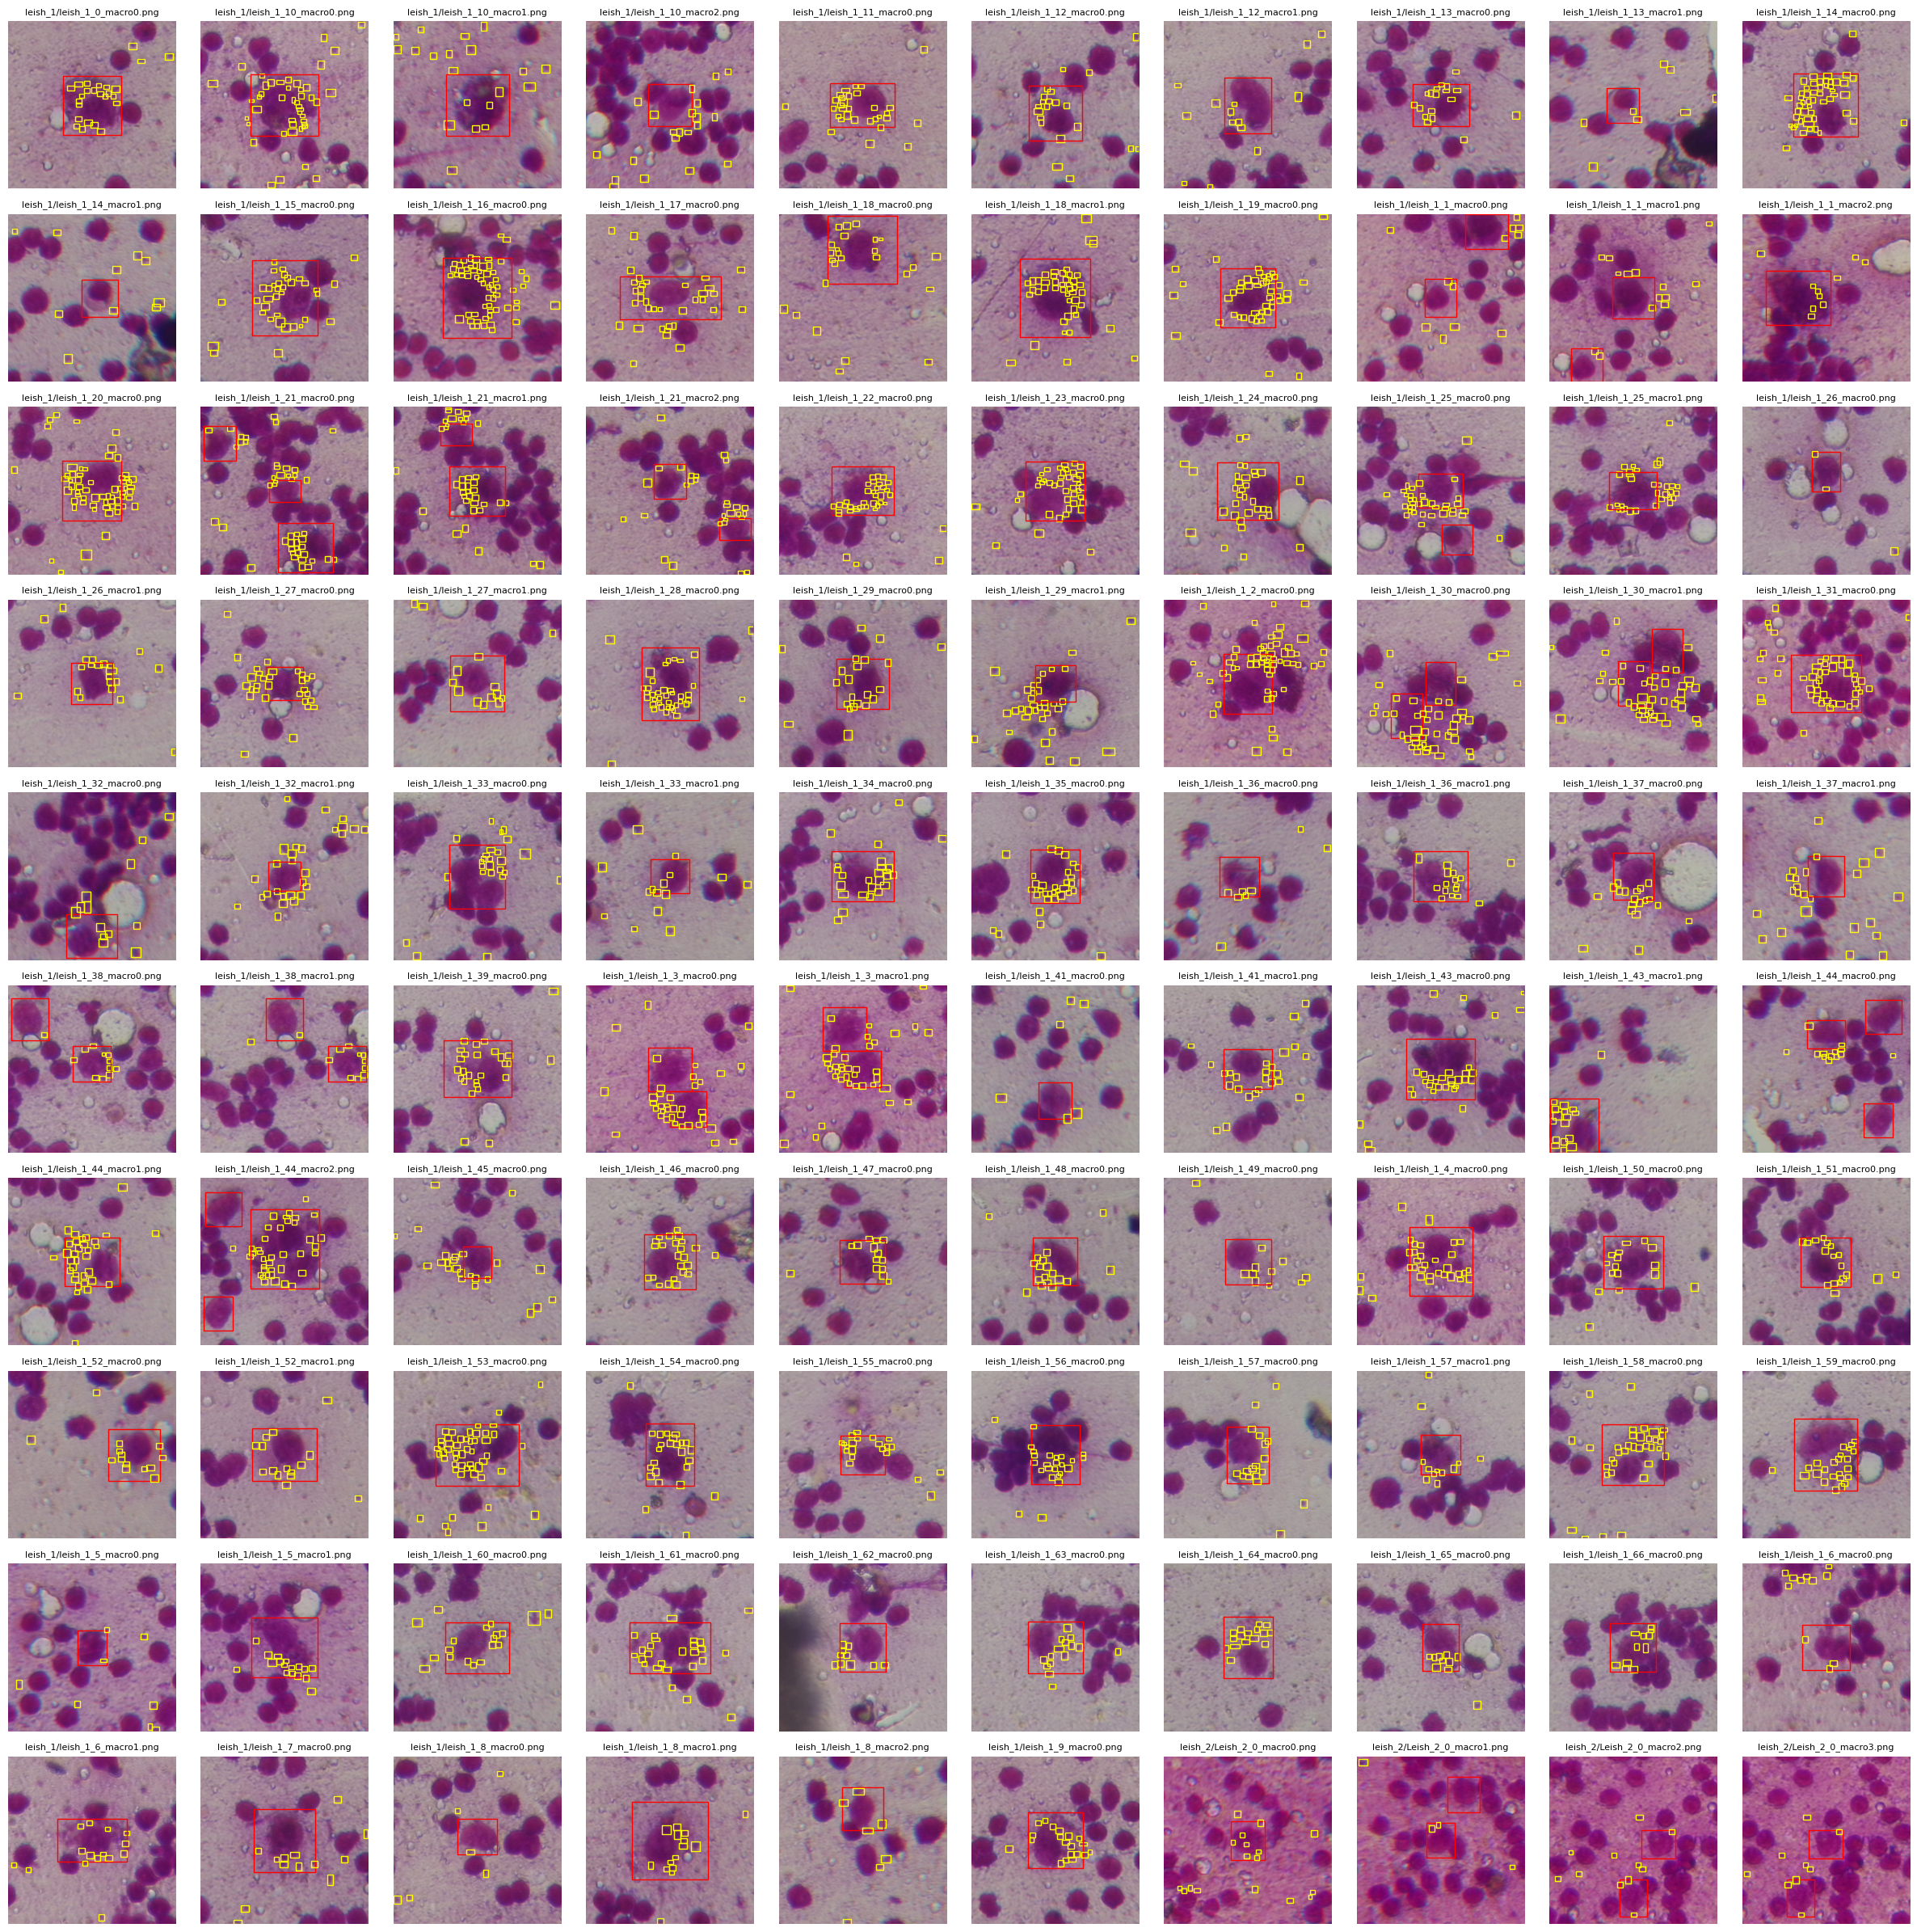

In [15]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Coleta até 100 recortes gerados para inspeção visual
arquivos_recortes = []
for lamina in sorted(os.listdir(diretorio_recortes)):
    pasta_lamina = os.path.join(diretorio_recortes, lamina)
    if not os.path.isdir(pasta_lamina):
        continue

    for arquivo in sorted(os.listdir(pasta_lamina)):
        if arquivo.endswith(extensao):
            arquivos_recortes.append((lamina, arquivo))

limite = min(100, len(arquivos_recortes))
if limite == 0:
    print("Nenhum recorte encontrado para visualizar.")
else:
    fig, axes = plt.subplots(10, 10, figsize=(24, 24))
    axes = axes.flatten()

    for ax, (lamina, arquivo) in zip(axes, arquivos_recortes[:limite]):
        img_path = os.path.join(diretorio_recortes, lamina, arquivo)
        nome_base = os.path.splitext(arquivo)[0]

        with Image.open(img_path) as img:
            largura_recorte, altura_recorte = img.size
            ax.imshow(img)

            txt_path = os.path.join(diretorio_recortes, lamina, f"{nome_base}.txt")
            if os.path.exists(txt_path):
                with open(txt_path) as f:
                    for linha in f:
                        classe_id, xc, yc, w, h = map(float, linha.split())
                        xc, yc, w, h = xc * largura_recorte, yc * altura_recorte, w * largura_recorte, h * altura_recorte
                        x1, y1 = xc - w / 2, yc - h / 2
                        cor = 'red' if int(classe_id) == indice_macrofago else 'yellow'
                        ax.add_patch(patches.Rectangle((x1, y1), w, h, linewidth=1.0, edgecolor=cor, facecolor='none'))

            ax.set_title(f"{lamina}/{arquivo}", fontsize=8)
            ax.axis("off")

    for ax in axes[limite:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()